# Live demo: When couriers win, eWAKA grows
**Team 7 · Santa Clara University MSBA · Analytics Showdown, Fall 2026**
Sinhye Kim · Yan Wu · Wei-Chia Lin · Ethan Casey

This notebook is for switching away from the slides during the talk. Each section shows the live code behind one slide.

| After slide | Demo | Presenter |
|---|---|---|
| 5 | Where do orders get lost? | Yan |
| 6 | Too many orders at once | Vivien |
| 9 | Suspended couriers who don't come back | Vivien |
| 12 · 19 | Model C: how many couriers each hour | Sherry · Ethan |
| 16 | Impact: what fewer misses are worth | Ethan |
| 17 | Model A: orders we can still save | Ethan |
| 18 | Model B: who to coach this week | Ethan |

**Run:** put this notebook, `demand_forecast.py` and the two Excel files in one folder, then *Run All* (about a minute). Results are saved, so it can also be shown without running.
Full detail: `BoltSend_eWAKA_analysis.ipynb` and `BoltSend_eWAKA_prediction_models.ipynb`.

## Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

TEAL, ORANGE, RED, GREEN, GRAY, LIGHT = '#1B7A83', '#D4690F', '#B5392F', '#1F7A4D', '#6B7B74', '#C9D3CE'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 11})

hist = pd.read_excel('boltsend_rider_history.xlsx')
perf = pd.read_excel('boltsend_rider_perfomance.xlsx')
hist['dt'] = pd.to_datetime(hist['date'].str[:19])          # local Nairobi time
hist['day'] = hist['dt'].dt.normalize()
hist['moto'] = hist['vehicle_model'].isin(['eWAKA Jasiri', 'RhingGo M300'])
perf['day'] = pd.to_datetime(perf['report_date'])

NR, FIN, REJ = 'Driver did not respond', 'Finished', 'Driver rejected'
CUST = ['Rider cancelled', 'Rider did not show']               # 'Rider' = customer in this data
orders = hist[hist['optional_ride'].isna()].sort_values(['individual_identifier', 'dt']).copy()
bike = orders[~orders['moto'] & (orders['dt'] >= '2025-05-01') & (orders['dt'] < '2025-09-01')].copy()
moto = orders[orders['moto'] & (orders['dt'] >= '2026-05-01') & (orders['dt'] < '2026-09-01')].copy()
print(f"Bicycles May-Aug 2025: {len(bike):,} orders | Motorbikes May-Aug 2026: {len(moto):,} orders")

Bicycles May-Aug 2025: 45,947 orders | Motorbikes May-Aug 2026: 9,086 orders


## After slide 5 · Where do orders get lost?
What happened to every 100 orders. The big change is **courier didn't answer**.

Didn't answer: 6.9% -> 14.0%
Once they say yes, finished: bicycle 64.3% vs motorbike 66.8%


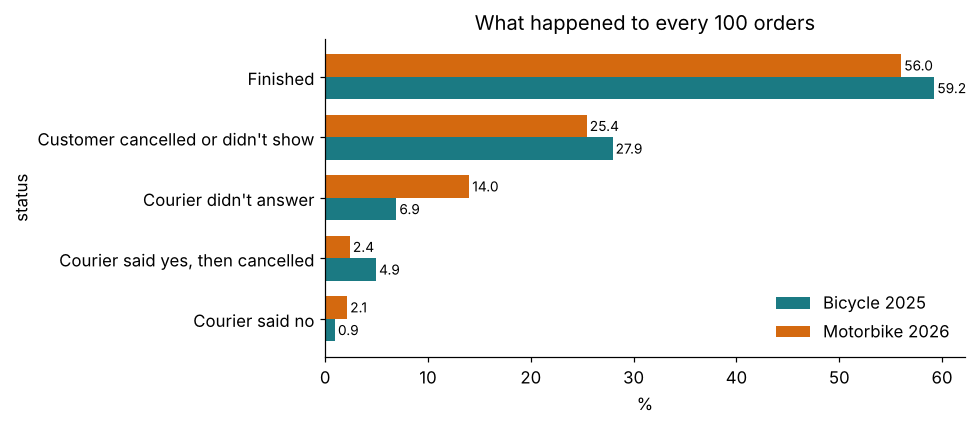

In [2]:
labels = {FIN: 'Finished', 'Rider cancelled': 'Customer cancelled or didn\'t show', 'Rider did not show': 'Customer cancelled or didn\'t show',
          NR: "Courier didn't answer", 'Driver cancelled': 'Courier said yes, then cancelled', REJ: 'Courier said no'}
mix = pd.DataFrame({name: df['status'].map(labels).value_counts(normalize=True) * 100 for name, df in [('Bicycle 2025', bike), ('Motorbike 2026', moto)]})
mix = mix.loc[['Finished', 'Customer cancelled or didn\'t show', "Courier didn't answer", 'Courier said yes, then cancelled', 'Courier said no']]
ax = mix.iloc[::-1].plot.barh(color=[TEAL, ORANGE], figsize=(9, 4), width=0.75)
ax.set(title='What happened to every 100 orders', xlabel='%'); ax.legend(frameon=False)
for c in ax.containers: ax.bar_label(c, fmt='%.1f', fontsize=9, padding=2)
plt.tight_layout(); plt.show()

def finish_after_yes(df): return (df.loc[~df['status'].isin([NR, REJ]), 'status'] == FIN).mean()
print(f"Didn't answer: {(bike['status']==NR).mean():.1%} -> {(moto['status']==NR).mean():.1%}")
print(f"Once they say yes, finished: bicycle {finish_after_yes(bike):.1%} vs motorbike {finish_after_yes(moto):.1%}")

## After slide 6 · Too many orders at once
The more orders a courier gets in one hour, the fewer get done. Orders that arrive mid-trip are missed about 1 in 4 times.

Missed when already on a trip: 23.4% vs 13.2% otherwise


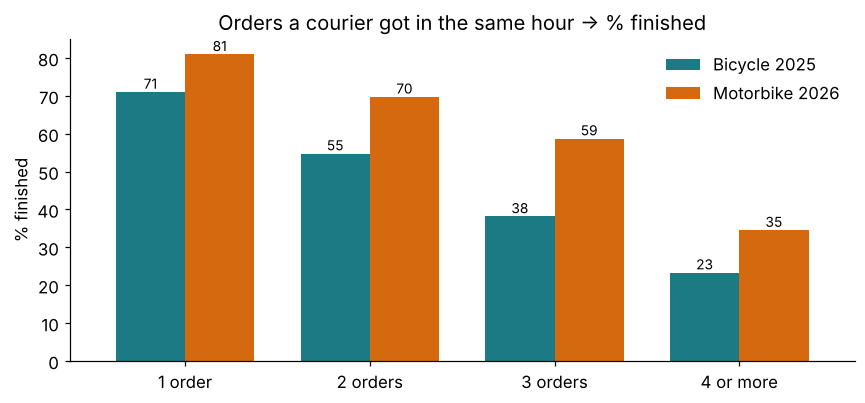

In [3]:
def by_load(df):
    load = df.groupby(['individual_identifier', df['dt'].dt.floor('h')])['status'].transform('size').clip(upper=4)
    return (df['status'] == FIN).groupby(load).mean() * 100
load = pd.DataFrame({'Bicycle 2025': by_load(bike), 'Motorbike 2026': by_load(moto)})
load.index = ['1 order', '2 orders', '3 orders', '4 or more']
ax = load.plot.bar(color=[TEAL, ORANGE], figsize=(8, 3.8), rot=0, width=0.75)
ax.set(title='Orders a courier got in the same hour → % finished', ylabel='% finished'); ax.legend(frameon=False)
for c in ax.containers: ax.bar_label(c, fmt='%.0f', fontsize=9)
plt.tight_layout(); plt.show()

m = moto.copy()
m['fin_end'] = pd.to_datetime(m['fare_finalised'].str[:19], errors='coerce')
m['busy_until'] = m.groupby('individual_identifier')['fin_end'].transform(lambda s: s.shift(1).cummax())
mid_trip = m['busy_until'] > m['dt']
print(f"Missed when already on a trip: {(m.loc[mid_trip, 'status']==NR).mean():.1%} vs {(m.loc[~mid_trip, 'status']==NR).mean():.1%} otherwise")

## After slide 9 · Suspended couriers who don't come back
New motorbike couriers from April 2026. Who came back after a suspension, and who stayed?

In [4]:
ids = hist.loc[hist['moto'], 'individual_identifier'].unique()
span = orders[orders['individual_identifier'].isin(ids)].groupby('individual_identifier')['dt'].agg(['min', 'max'])
new = span[span['min'] >= '2026-04-01'].copy()
new['left'] = new['max'] < '2026-08-01'
new['suspended'] = new.index.isin(perf.loc[perf['status'] == 'Suspended', 'individual_identifier'])
last = perf.sort_values('day').groupby('individual_identifier')['status'].last().reindex(new.index)
new['still_suspended'] = (last == 'Suspended') | ((last == 'Deactivated') & new['suspended'])

s = new[new['suspended']]
came_back, stuck = s[~s['still_suspended']], s[s['still_suspended']]
print(f"{len(new)} new couriers, {len(s)} got suspended")
print(f"  Came back:        {len(came_back)} -> {(~came_back['left']).sum()} of {len(came_back)} stayed")
print(f"  Stayed suspended: {len(stuck)} -> {stuck['left'].sum()} of {len(stuck)} left")

23 new couriers, 14 got suspended
  Came back:        6 -> 5 of 6 stayed
  Stayed suspended: 8 -> 7 of 8 left


## After slides 12 and 19 · Model C: how many couriers each hour (Ethan)
`demand_forecast.py` predicts orders for every weekday × hour and turns them into couriers needed.

Courier-hours needed per day: 74 | online per day: 28
Couriers needed at 16:00, by weekday: 5-7


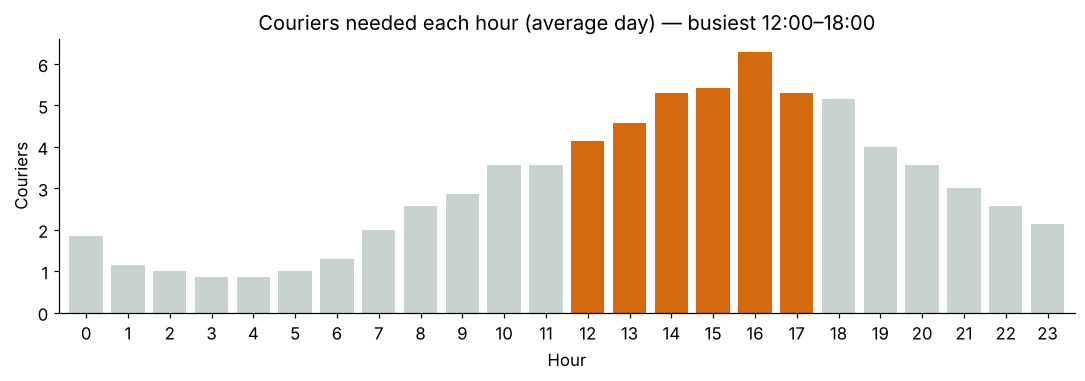

In [5]:
import runpy, contextlib, io
with contextlib.redirect_stdout(io.StringIO()):          # the script prints long tables; we show the key result below
    runpy.run_path('demand_forecast.py', run_name='__main__')
fc = pd.read_csv('demand_forecast.csv')
fc['hour'] = fc['hour'].str[:2].astype(int)
need = fc.groupby('hour')['slots'].mean()
ax = need.plot.bar(color=[ORANGE if 12 <= h < 18 else LIGHT for h in need.index], figsize=(10, 3.6), rot=0, width=0.8)
ax.set(title='Couriers needed each hour (average day) — busiest 12:00–18:00', xlabel='Hour', ylabel='Couriers')
plt.tight_layout(); plt.show()

moto_ids = moto['individual_identifier'].unique()
p = perf[perf['individual_identifier'].isin(moto_ids) & (perf['day'] >= '2026-05-01') & (perf['day'] < '2026-09-01')]
have = p['online_time_min'].sum() / 60 / 123
print(f"Courier-hours needed per day: {fc.groupby('weekday')['slots'].sum().mean():.0f} | online per day: {have:.0f}")
print(f"Couriers needed at 16:00, by weekday: {fc.loc[fc['hour']==16, 'slots'].min()}-{fc.loc[fc['hour']==16, 'slots'].max()}")

## After slide 16 · What fewer misses are worth
If no-response and rejections go back to 2025 levels and accepted orders still finish at today's rate.

In [6]:
accept_2025 = 1 - bike['status'].isin([NR, REJ]).mean()
with_fixes = accept_2025 * finish_after_yes(moto)
now = (moto['status'] == FIN).mean()
per_day = moto.groupby(['individual_identifier', 'day']).size().mean()
fare = moto.loc[moto['status'] == FIN, 'trip_priceksh'].mean()
print(f"Orders finished: {now:.1%} now -> {with_fixes:.1%} with fixes")
print(f"Per courier per day: +{per_day * (with_fixes - now):.1f} orders, +KSh {per_day * (with_fixes - now) * fare:.0f}")

Orders finished: 56.0% now -> 61.6% with fixes
Per courier per day: +0.9 orders, +KSh 182


## After slide 17 · Model A: orders we can still save
Trained on Jan 2025 – Feb 2026, tested on Mar – Aug 2026, using only what is known when an order is sent.

Riskiest group: 492 missed orders in 6 months = about 82 a month
That is 29% of all missed orders (46% missed vs 16% on average)


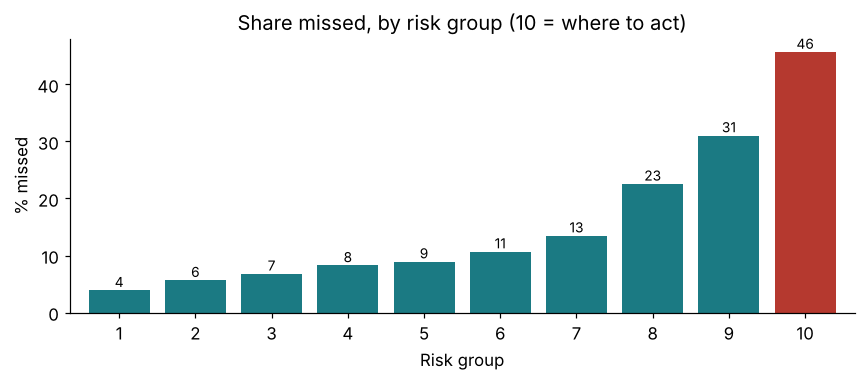

In [7]:
o = orders.reset_index(drop=True).copy()
o['nr'] = (o['status'] == NR).astype(int)
o['moto'] = o['moto'].astype(int)
g = o.groupby('individual_identifier')
o['gap_min'] = ((o['dt'] - g['dt'].shift()).dt.total_seconds() / 60).fillna(1440).clip(upper=1440)
o['burst'] = (o['gap_min'] < 10).astype(int)
def last60(df):
    t = df['dt'].values.astype('datetime64[s]').astype(np.int64)
    return pd.Series(np.arange(len(t)) - np.searchsorted(t, t - 3600, side='left'), index=df.index)
o['offers_last60'] = g.apply(last60).reset_index(level=0, drop=True)
o['fin_end'] = pd.to_datetime(o['fare_finalised'].str[:19], errors='coerce')
o['intrip'] = (g['fin_end'].transform(lambda s: s.shift(1).cummax()) > o['dt']).astype(int)
o['hour'], o['dow'] = o['dt'].dt.hour, o['dt'].dt.dayofweek
o['offers_today'] = o.groupby(['individual_identifier', 'day']).cumcount()
o['hrs_since_first_today'] = (o['dt'] - o.groupby(['individual_identifier', 'day'])['dt'].transform('min')).dt.total_seconds() / 3600
o['prev_nr'] = g['nr'].shift().fillna(0)
o['nr_rate_prev50'] = g['nr'].transform(lambda s: s.shift().rolling(50, min_periods=5).mean())
o['hist_n'] = g.cumcount()
FEATS = ['gap_min', 'burst', 'offers_last60', 'intrip', 'hour', 'dow', 'offers_today', 'hrs_since_first_today', 'prev_nr', 'nr_rate_prev50', 'hist_n', 'moto']

train, test = o[o['dt'] < '2026-03-01'].copy(), o[o['dt'] >= '2026-03-01'].copy()
for d in (train, test): d['nr_rate_prev50'] = d['nr_rate_prev50'].fillna(train['nr'].mean())
model_a = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, random_state=0).fit(train[FEATS], train['nr'])
test['risk_group'] = pd.qcut(model_a.predict_proba(test[FEATS])[:, 1], 10, labels=False) + 1

share = test.groupby('risk_group')['nr'].mean() * 100
ax = share.plot.bar(color=[RED if i == 10 else TEAL for i in share.index], figsize=(8, 3.6), rot=0, width=0.8)
ax.set(title='Share missed, by risk group (10 = where to act)', xlabel='Risk group', ylabel='% missed')
for c in ax.containers: ax.bar_label(c, fmt='%.0f', fontsize=9)
plt.tight_layout(); plt.show()

top = test[test['risk_group'] == 10]
months = 6
print(f"Riskiest group: {top['nr'].sum():,} missed orders in {months} months = about {top['nr'].sum() / months:.0f} a month")
print(f"That is {top['nr'].sum() / test['nr'].sum():.0%} of all missed orders ({top['nr'].mean():.0%} missed vs {test['nr'].mean():.0%} on average)")

## After slide 18 · Model B: who to coach this week
Predicts a bad week (fewer than 50% of orders finished) from this week's behaviour. Trained on 2025, tested on 2026.

In [8]:
o['wk'] = o['dt'].dt.to_period('W-SUN').dt.start_time
for c, cond in [('fin', o['status'] == FIN), ('rej', o['status'] == REJ), ('cust', o['status'].isin(CUST)), ('dcx', o['status'] == 'Driver cancelled')]:
    o[c] = cond.astype(int)
w = o.groupby(['individual_identifier', 'wk']).agg(offers=('nr', 'size'), nr=('nr', 'mean'), rej=('rej', 'mean'), fin=('fin', 'mean'), cust=('cust', 'mean'),
    dcx=('dcx', 'mean'), intrip=('intrip', 'mean'), burst=('burst', 'mean'), active_days=('day', 'nunique'), moto=('moto', 'max'))
fo = o[o['status'] == FIN]
w = w.join(fo.groupby(['individual_identifier', 'wk']).agg(pickup=('pickup_duration_min', 'median'), ride=('ride_duration_min', 'median'),
                                                          dist=('distancekm', 'median'), fare=('trip_priceksh', 'sum')))
perf['wk'] = perf['day'].dt.to_period('W-SUN').dt.start_time
w = w.join(perf.groupby(['individual_identifier', 'wk']).agg(online_h=('online_time_min', lambda s: s.sum() / 60), util=('utilisation', 'mean'),
    acc=('total_acceptance_rate', 'mean'), rating=('average_driver_rating', lambda s: s[s > 0].mean()), score=('driver_score', 'mean'),
    susp=('status', lambda s: (s != 'Active').any())), how='left')
w = w.reset_index().sort_values(['individual_identifier', 'wk'])
w['tenure_wk'] = (w['wk'] - w.groupby('individual_identifier')['wk'].transform('min')).dt.days // 7
w['fare_per_h'] = w['fare'] / w['online_h'].replace(0, np.nan)
gw = w.groupby('individual_identifier')
w['next_wk'], w['next_fin'], w['next_offers'] = gw['wk'].shift(-1), gw['fin'].shift(-1), gw['offers'].shift(-1)
w = w[((w['next_wk'] - w['wk']).dt.days == 7) & (w['offers'] >= 10) & (w['next_offers'] >= 10)].copy()
w['bad_week'] = (w['next_fin'] < 0.5).astype(int)

F = ['offers', 'nr', 'rej', 'fin', 'cust', 'dcx', 'intrip', 'burst', 'active_days', 'pickup', 'ride', 'dist',
     'online_h', 'util', 'acc', 'rating', 'score', 'susp', 'tenure_wk', 'moto', 'fare_per_h']
trB, teB = w[w['wk'] < '2026-01-01'], w[w['wk'] >= '2026-01-01'].copy()
med = trB[F].astype(float).median()
model_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(trB[F].astype(float).fillna(med), trB['bad_week'])
teB['chance_bad_week'] = model_b.predict_proba(teB[F].astype(float).fillna(med))[:, 1]

week = teB.groupby('wk').size().idxmax()
lst = teB[teB['wk'] == week].sort_values('chance_bad_week', ascending=False).head(5)
out = pd.DataFrame({'courier': lst['individual_identifier'].str[:8].values,
                    'chance of a bad week': (lst['chance_bad_week'] * 100).round().astype(int).astype(str).add('%').values,
                    "didn't answer": (lst['nr'] * 100).round().astype(int).astype(str).add('% of orders').values})
print('Coaching list, week of', week.date())
out

Coaching list, week of 2026-02-09


,courier,chance of a bad week,didn't answer
0,Courier 01,94%,46% of orders
1,Courier 02,92%,44% of orders
2,Courier 03,86%,56% of orders
3,Courier 04,82%,20% of orders
4,Courier 05,80%,46% of orders
